# Tractor-trailer path following: backstepping + online sparse GP

All model, controller, GP and plotting code lives in the `truck_trailer` package next to this notebook.
This notebook only sets up and runs the experiments.

| step | cell |
|---|---|
| 1 | imports |
| 2 | LF design model, controllability, strict-feedback form, controller |
| 3 | baseline run without GP (figure eight) |
| 4 | residual dataset + semi-parametric sparse GP banks |
| 5 | scenario 1: figure eight, mass/inertia uncertainty |
| 6 | scenarios 2-4: U-turn, lane change, straight line with road bank |
| 7 | figures (SVG) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import truck_trailer as tt
from truck_trailer import figures, plotting

## 1. Design model and controller

In [2]:
params = tt.default_params()
V_design = 10.0                                   # design speed of the LF model [m/s]

# controller: LF model -> strict-feedback form z = T x_LF -> command-filtered backstepping
ctrl, ref, lf = tt.design_controller(params, V_design, C=[0.8, 1.1, 1.35, 2.0, 6.2, 18.0], wf=32.0, zeta=0.99)

A4, B1_4, _ = tt.lateral_state_space(V_design, params)
print("controllability rank, lateral dynamics:     ", tt.controllability_rank(A4, B1_4))
print("controllability rank, kinematics + dynamics:", tt.controllability_rank(lf["A_big"], lf["B1_big"]))
print("T A_big T^-1 =\n", ctrl["T"] @ lf["A_big"] @ np.linalg.inv(ctrl["T"]))
print("a =", ctrl["a"], "\nb =", ctrl["b"], "\nc =", ctrl["c"])

speed = tt.make_speed(vx_ref=10.0, params_ctrl=params)   # the controller only knows the nominal parameters
tire_model_HF = "pacejka"
dt_s = 0.005

LF design at V = 10 m/s | zeros u->e: [-11.723+0.j     -2.285+3.003j  -2.285-3.003j  -1.146+0.j   ]
nominal closed loop: max Re = -0.802, max|eig| = 54.4
controllability rank, lateral dynamics:      4
controllability rank, kinematics + dynamics: 6
T A_big T^-1 =
 [[ 0.00000000e+00  1.00000000e+00  9.96806855e-16  4.65402871e-16
   8.11419963e-17  4.19751381e-18]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00 -8.58868983e-15
  -1.78457821e-15 -8.34639318e-17]
 [ 0.00000000e+00  0.00000000e+00  5.73929987e-14  1.00000000e+00
   2.42694022e-14  1.27338250e-15]
 [ 0.00000000e+00  0.00000000e+00  1.79068749e-12  2.37767434e-12
   1.00000000e+00  1.78987369e-14]
 [ 0.00000000e+00  0.00000000e+00 -2.07340309e-11 -8.82245735e-12
  -1.46166876e-12  1.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00 -2.63690686e+02 -4.60494708e+02
  -1.78590291e+02 -2.39073611e+01]]
a = [   0.            0.         -263.69068601 -460.4947077  -178.5902906
  -23.90736109] 
b = 1.0000000000003109 
c = [ 0.001573

## 2. Baseline controller: figure eight without GP

[none] 52440 steps in 34 s
max |steer|           = 5.53 deg
max |e| after 30 s    = 5.331e-02 m
RMS e  after 30 s     = 1.374e-02 m
max |e_int - e_geo|   = 1.025e-11 m


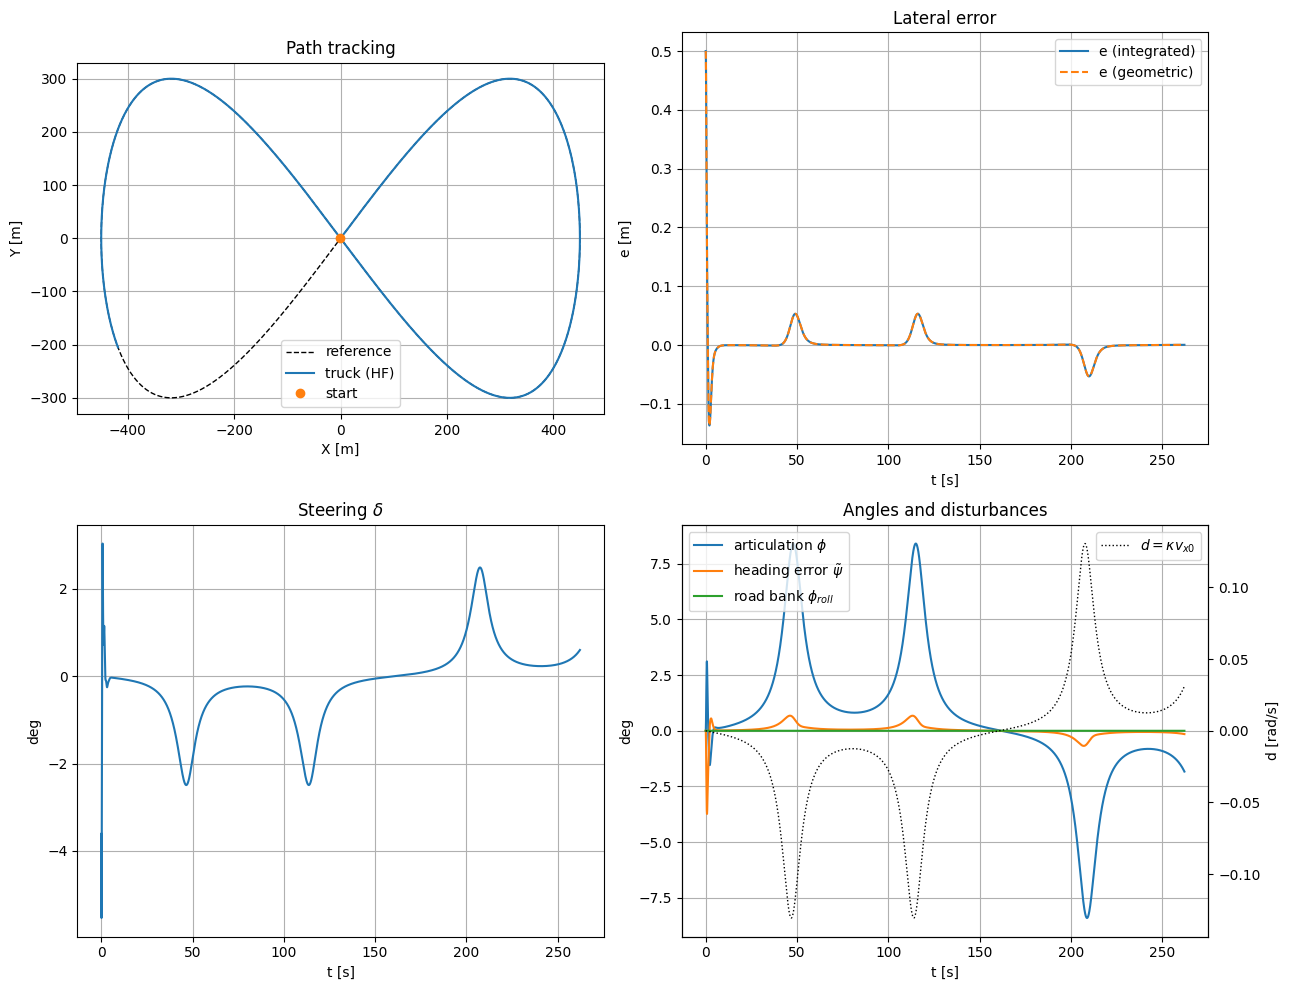

In [4]:
path_eight = tt.make_path("eight", A_path=450.0, B_path=300.0)
res0 = tt.run_scenario("none", None, None, ctrl, ref, path_eight, speed, tt.make_road(0.0, feedforward=True),
                       params, tire_model_HF, dt_s, laps=0.8, e_init=0.5)
tt.tracking_summary(res0, settle_time=30.0)
plotting.plot_tracking_overview(res0, path_eight)
# plotting.plot_hf_states(res0)
plt.show()

## 3. Residual dataset and semi-parametric sparse GP banks
One GP per residual output: $f(\xi)=\theta^\top\phi(\xi)+r(\xi)$, $r\sim\mathcal{GP}(0,\kappa)$, basis $\phi=[1,\tanh(\xi),\exp(-\|\xi-c_j\|^2/l)]$.

* `aware`: the GP sees the road-bank input known to the controller
* `unaware`: the GP does not see it, so an unmodelled bank is learned online as part of the residual

In [5]:
model_HF_data = tt.TruckTrailerDynamics(params, tire_model=tire_model_HF)
X_data, Y_data = tt.generate_residual_dataset(model_HF_data, lf, params, rng=np.random.default_rng(0),
                                              n_track=700, n_trans=300)
print("X:", X_data.shape, tt.GP_FEATURE_NAMES)
print("Y:", Y_data.shape, tt.GP_TARGET_NAMES)

normalizer = tt.make_feature_normalizer(X_data)
X_data_norm = tt.normalize_features(X_data, normalizer)
sp_banks = tt.train_residual_gp_banks(X_data_norm, Y_data, n_pool=30, n_centers=64, n_hyp=300)

X: (1000, 11) ['e', 'psi_tilde', 'vy0', 'r0', 'phi_dot', 'phi', 'vx0', 'delta', 'F_xf', 'd_roll', 'kappa']
Y: (1000, 7) ['res_e', 'res_psi_tilde', 'res_vy0', 'res_r0', 'res_phi_dot', 'res_phi', 'res_vx0']
--- GP 'aware': masked features [7]
--- GP 'unaware': masked features [7, 9]


## 4. Closed-loop scenarios
Same design model and controller everywhere; only the plant, path, road bank and initial speed change.

In [6]:
# GP options: F_hat low-pass, GP evaluation / online-update intervals, vx0' residual gain, reliability guard
gp_opts = {"tau_F": 2.0, "gp_every": 4, "learn_every": 20, "gain_vx": 0.5, "ood_limit": 4.0, "forget": 1.0}
scenario_runs = {}

def run(cases, path, params_HF=params, e_init=0.0, speed=speed, **kw):
    return tt.run_cases(cases, sp_banks, normalizer, ctrl, ref, path, speed, params_HF, tire_model_HF,
                        dt_s, e_init, gp_opts=gp_opts, **kw)

# ---- Scenario 1: figure eight, uncertain masses and yaw inertias, no road bank
print("===== 1. infinity figure: uncertain masses and inertias =====")
params_HF = tt.make_hf_params(params, scale={"M0": 1.3, "M1": 1.7, "Iz0": 1.3, "Iz1": 1.7})
results = run(tt.standard_cases(tt.make_road(0.0)), path_eight, params_HF, e_init=0.5, laps=1.0)
tt.report(results, speed["vx_ref"], t_from=0.0)
scenario_runs["1. infinity figure: mass and inertia uncertainty"] = dict(results=results, path=path_eight,
                                                                         t_from=0.0, win_s=20.0)

===== 1. infinity figure: uncertain masses and inertias =====
[no GP] 65299 steps in 35 s
[GP (offline only)] 65299 steps in 45 s
[GP online (lateral)] 65299 steps in 77 s
[GP online + vx0' residual (gain 0.5)] 65299 steps in 70 s
(t >= 0 s; percentages relative to 'no GP')
controller                                RMS e [cm]  speed RMS/max steer RMS  F_xf RMS/max [kN]
no GP                                   12.8 (  +0%) 0.023/0.076     0.71deg     0.22/0.7     
GP (offline only)                       15.7 ( +22%) 0.025/0.084     1.23deg     0.24/0.8     
GP online (lateral)                      5.1 ( -60%) 0.023/0.076     0.72deg     0.22/0.7     
GP online + vx0' residual (gain 0.5)     5.6 ( -57%) 0.019/0.047     0.76deg     0.22/0.8     
residual left after compensation [SI], rows vy0', r0', phi_ddot, vx0':
  no GP                                [0.171  0.0197 0.0127 0.0232]
  GP (offline only)                    [0.1735 0.0504 0.0698 0.0257]
  GP online (lateral)                  

In [7]:
bank = 0.1                                         # unknown road bank [rad]

# ---- Scenario 2: U-turn R = 60 m
print("\n===== 2. U-turn R = 60 m, unknown road bank 0.1 rad =====")
path_uturn = tt.make_path("uturn", R=60.0, L_ramp=40.0)
res_u, extra_u = run(tt.bank_cases(bank), path_uturn), run(tt.unaware_extra_cases(bank), path_uturn)
tt.print_performance_table(res_u + extra_u, speed["vx_ref"], 0.0); tt.print_gp_reliability(res_u, 0.0)
scenario_runs["2. U-turn R = 60 m, unknown road bank"] = dict(results=res_u, extra_results=extra_u,
                                                              path=path_uturn, t_from=0.0, win_s=5.0)

# ---- Scenario 3: lane change (S-shape), 3.5 m in 40 m
print("\n===== 3. lane change, unknown road bank 0.1 rad =====")
path_lane = tt.make_path("lanechange", dy=3.5, L=40.0)
res_l, extra_l = run(tt.bank_cases(bank), path_lane), run(tt.unaware_extra_cases(bank), path_lane)
tt.print_performance_table(res_l + extra_l, speed["vx_ref"], 0.0); tt.print_gp_reliability(res_l, 0.0)
scenario_runs["3. lane change (S-shape), unknown road bank"] = dict(results=res_l, extra_results=extra_l,
                                                                    path=path_lane, t_from=0.0, win_s=5.0)

# ---- Scenario 4: straight line, initial speed 13 m/s (reference 10 m/s), road bank
print(f"\n===== 4. straight line, bank {bank} rad, initial speed 13 m/s =====")
path_line = tt.make_path("line", L=700.0)
line_kw = dict(T_end=40.0, vx_init=13.0)
cases = [dict(mode="none", label="no GP, controller unaware", road=tt.make_road(bank, False)),
         dict(mode="none", label="no GP, controller aware", road=tt.make_road(bank, True)),
         dict(mode="gp_online", label="GP unaware", bank="unaware", road=tt.make_road(bank, False), opts={"forget": 0.95}),
         dict(mode="gp_online", label="GP aware + controller aware", bank="aware", road=tt.make_road(bank, True))]
res_line = run(cases, path_line, **line_kw)
res_line += run([dict(mode="none", label="no GP, controller aware, speed loop OFF", road=tt.make_road(bank, True))],
                path_line, speed={**speed, "k_vx": 0.0}, **line_kw)          # longitudinal controller off
extra_line = run(tt.unaware_extra_cases(bank), path_line, **line_kw)
tt.print_performance_table(res_line + extra_line, speed["vx_ref"], 0.0); tt.print_gp_reliability(res_line, 0.0)
scenario_runs["4. straight line, 13 m/s start, road bank 0.1 rad"] = dict(results_by_v0={13.0: res_line},
                                                                          extra_results=extra_line,
                                                                          path=path_line, t_from=0.0, win_s=5.0)


===== 2. U-turn R = 60 m, unknown road bank 0.1 rad =====
[no GP, controller unaware] 10171 steps in 6 s
[no GP, controller aware (feedforward)] 10171 steps in 6 s
[GP unaware] 10171 steps in 9 s
[GP online + vx0' residual] 10171 steps in 9 s
(t >= 0 s; percentages relative to 'no GP, controller unaware')
controller                                RMS e [cm]  speed RMS/max steer RMS  F_xf RMS/max [kN]
no GP, controller unaware               37.0 (  +0%) 0.026/0.092     2.28deg     0.39/1.2     
no GP, controller aware (feedforward)     4.5 ( -88%) 0.026/0.093     2.26deg     0.39/1.0     
GP unaware                               3.9 ( -89%) 0.027/0.097     2.31deg     0.40/1.2     
GP online + vx0' residual                6.3 ( -83%) 0.018/0.087     2.37deg     0.42/1.6     
residual left after compensation [SI], rows vy0', r0', phi_ddot, vx0':
  no GP, controller unaware            [0.3055 0.0696 0.0633 0.0428]
  no GP, controller aware (feedforward) [0.2529 0.0577 0.0541 0.041 ]
  GP

## 5. Figures (SVG)
Tracking-error plots per scenario, RMS bar chart, and HF states of "no GP" vs the best online GP.

saved figures_svg\S1_eight_cartesian_error_norm.svg
saved figures_svg\S1_eight_rolling_rms_e.svg
saved figures_svg\S1_eight_cartesian_error_components.svg
saved figures_svg\S1_eight_abs_e_distribution.svg
saved figures_svg\S1_eight_gp_quality_2sigma.svg
saved figures_svg\S2_uturn_cartesian_error_norm.svg
saved figures_svg\S2_uturn_rolling_rms_e.svg
saved figures_svg\S2_uturn_abs_e_distribution.svg
saved figures_svg\S2_uturn_cartesian_error_components.svg
saved figures_svg\S3_sshape_cartesian_error_norm.svg
saved figures_svg\S3_sshape_rolling_rms_e.svg
saved figures_svg\S3_sshape_abs_e_distribution.svg
saved figures_svg\S3_sshape_cartesian_error_components.svg
saved figures_svg\S4_line_lateral_error_norm.svg
saved figures_svg\S4_line_speed_vx0.svg
saved figures_svg\S4_line_cartesian_error_components.svg
$\infty$-shape: baseline 100.0% (12.8 cm), offline 122.5% (15.7 cm), online 40.1% (5.1 cm), online_vx 43.3% (5.6 cm)
       U-shape: baseline 100.0% (37.0 cm), online 10.6% (3.9 cm), onl

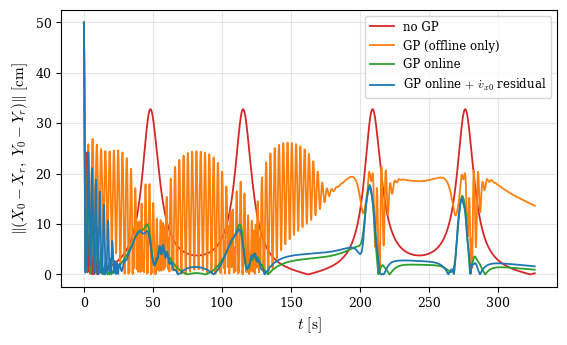

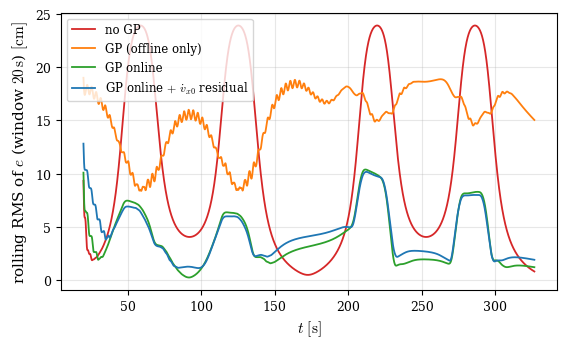

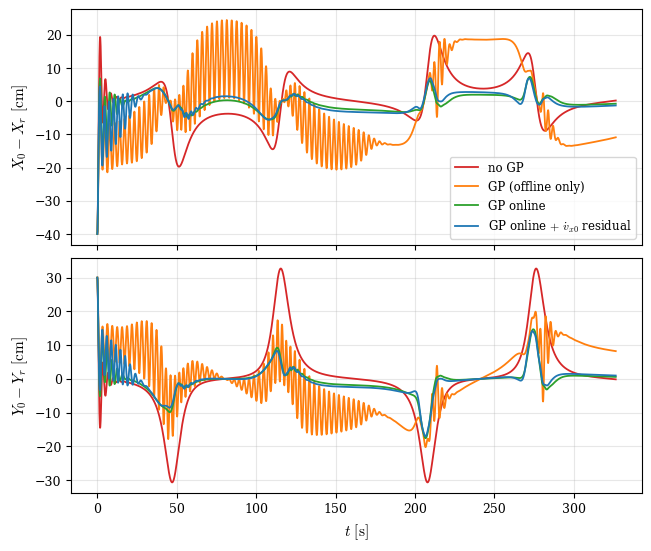

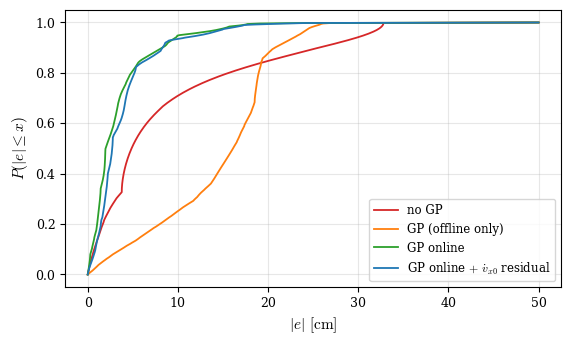

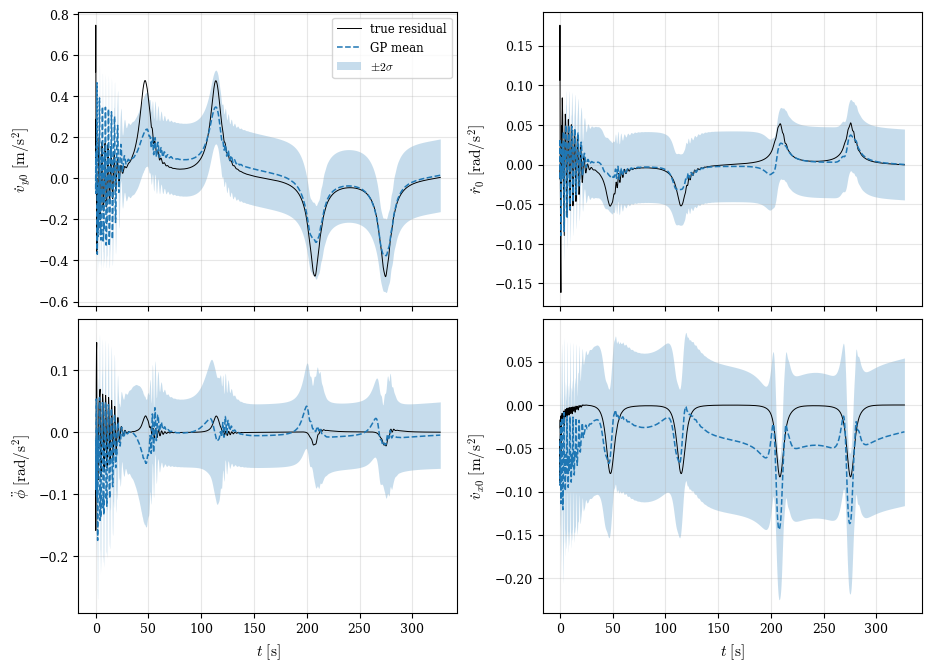

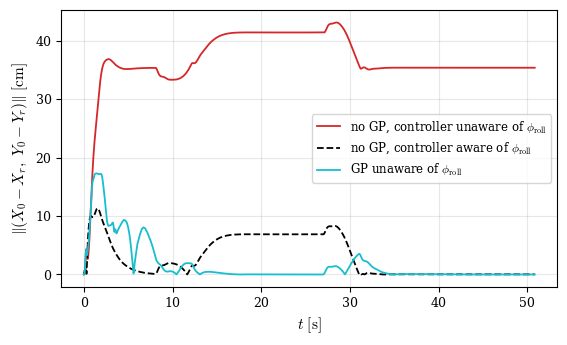

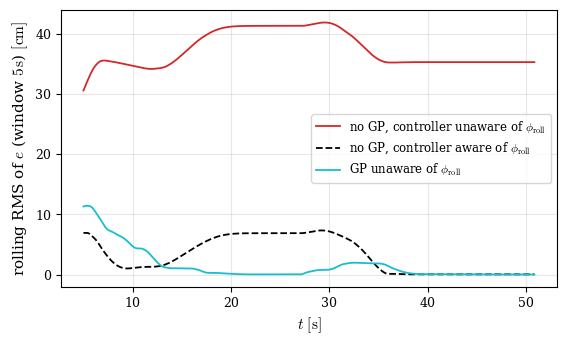

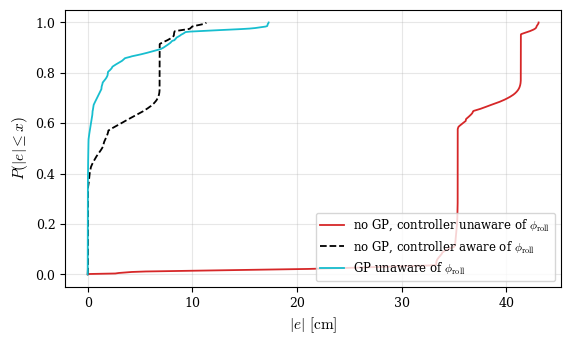

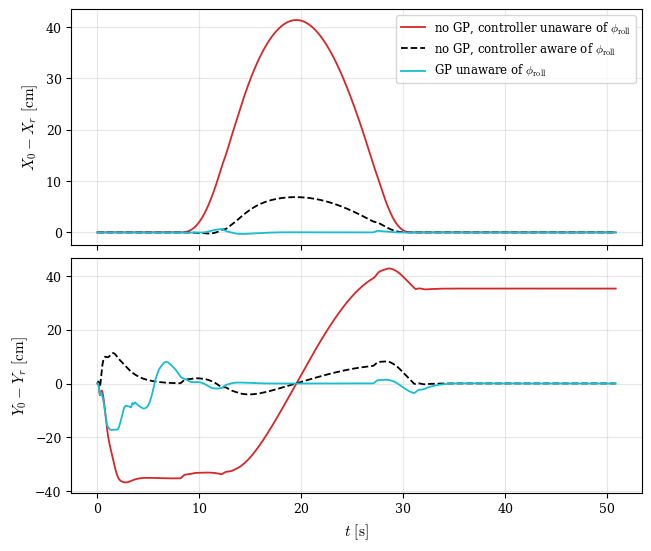

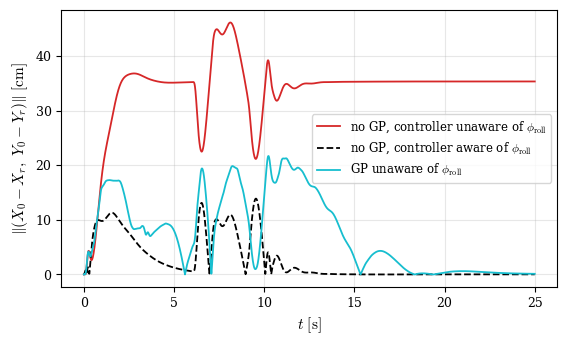

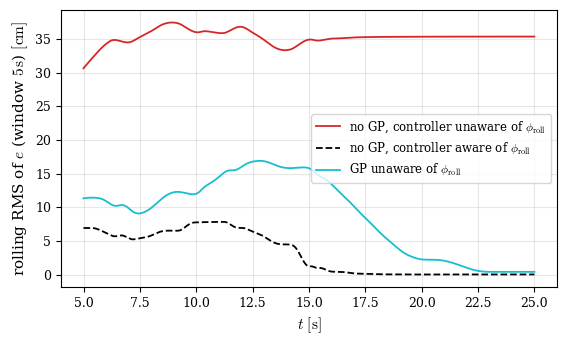

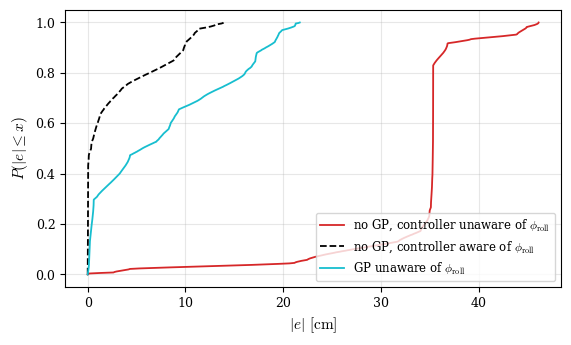

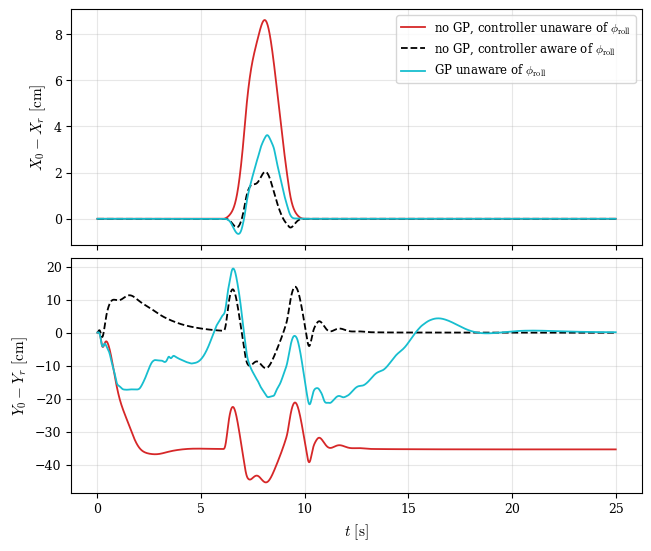

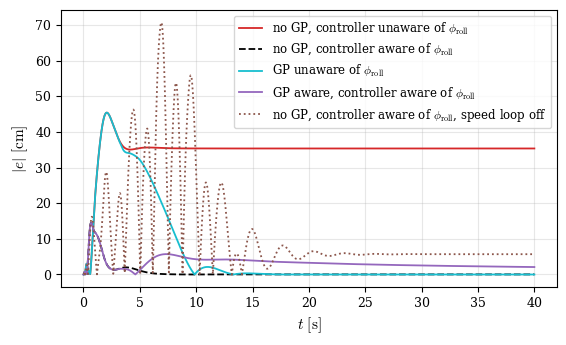

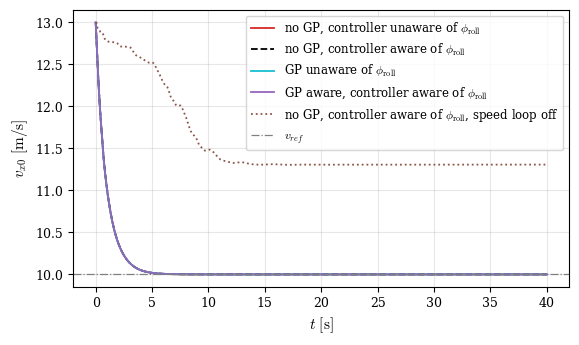

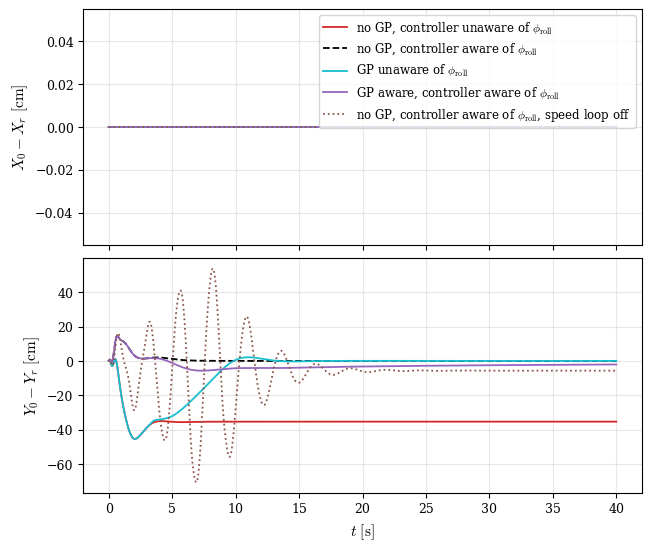

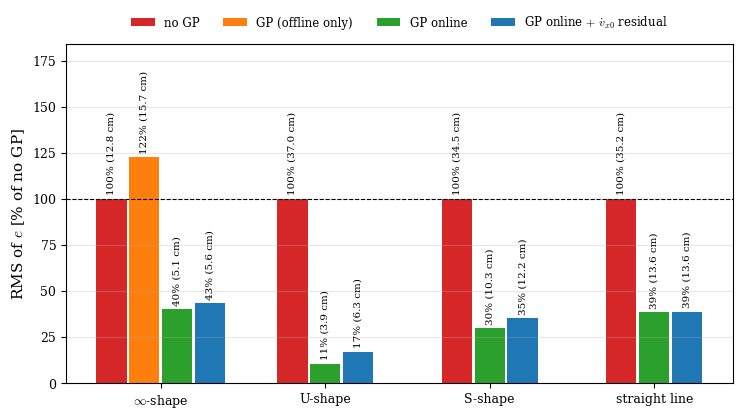

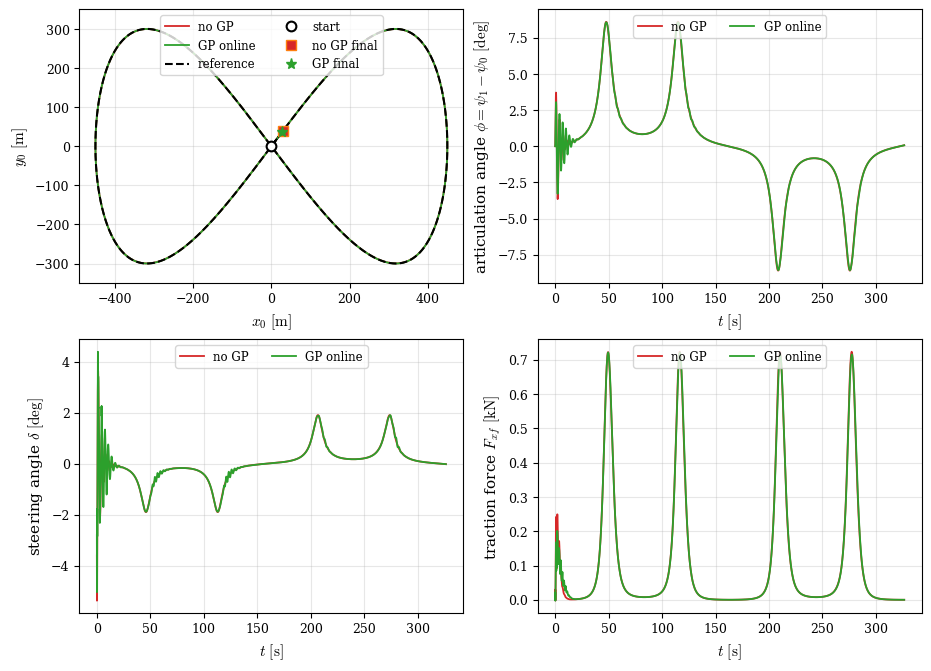

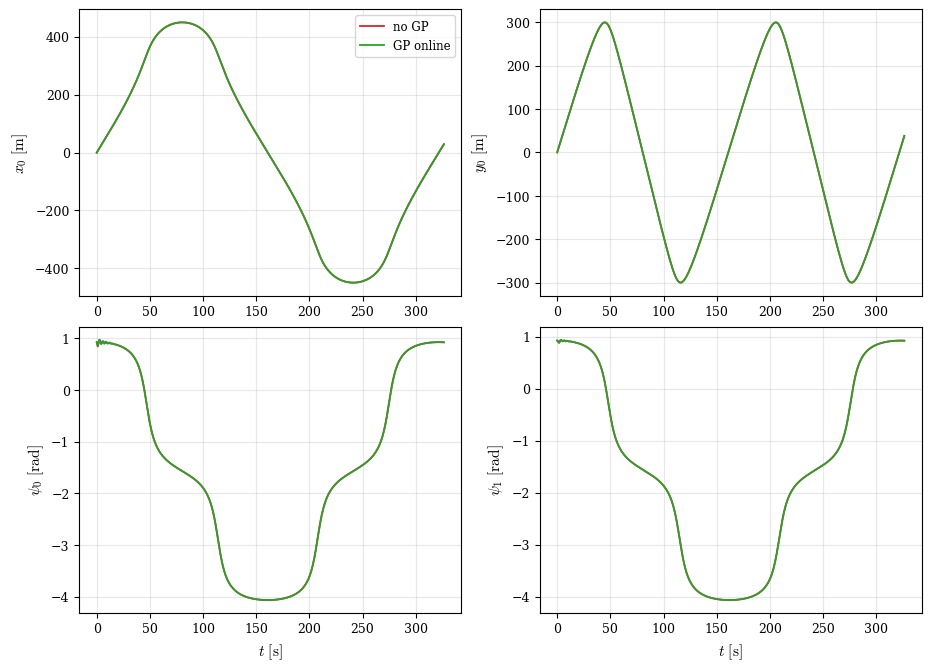

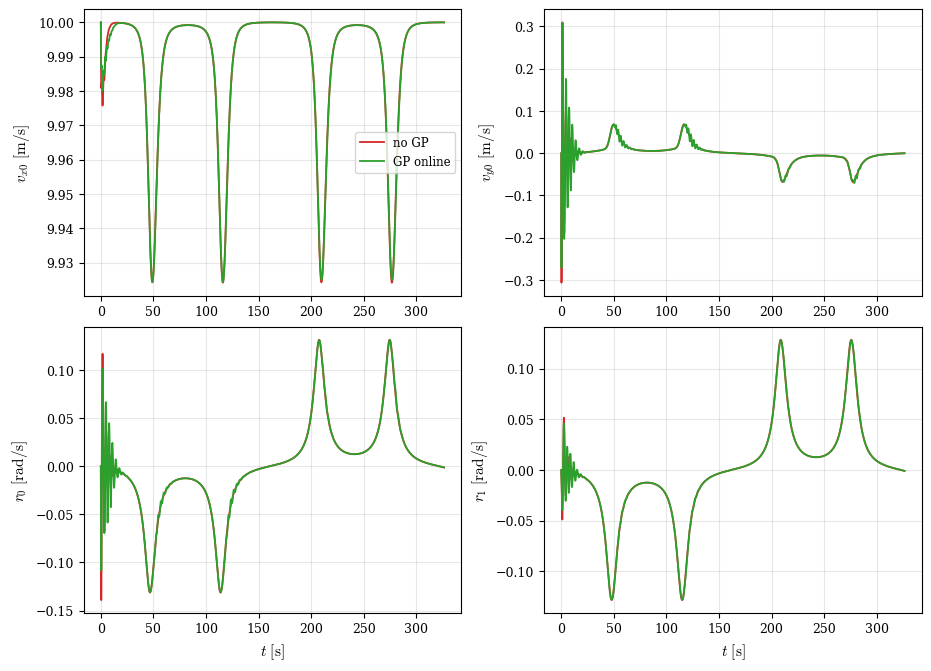

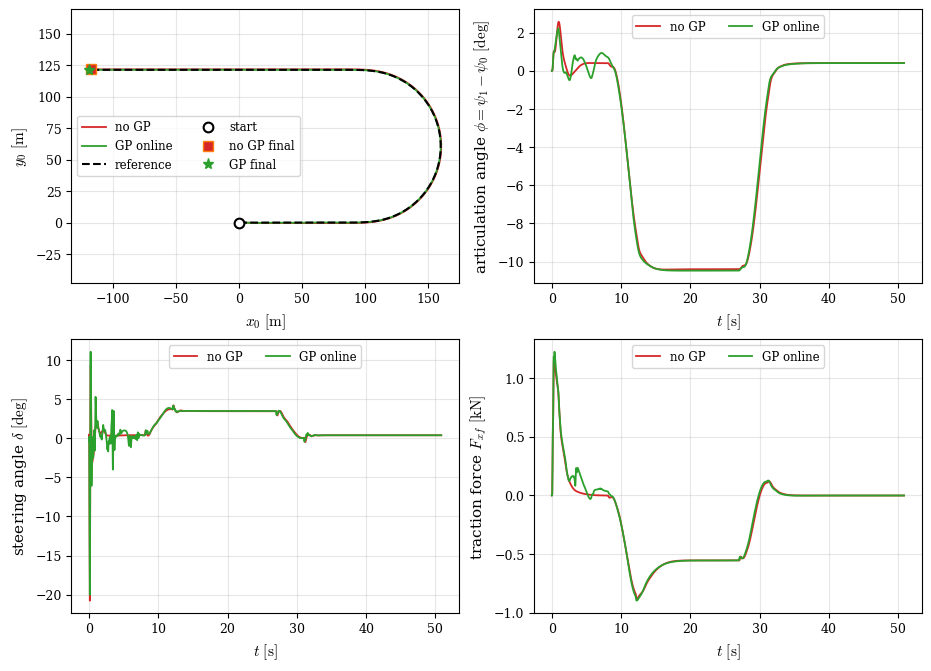

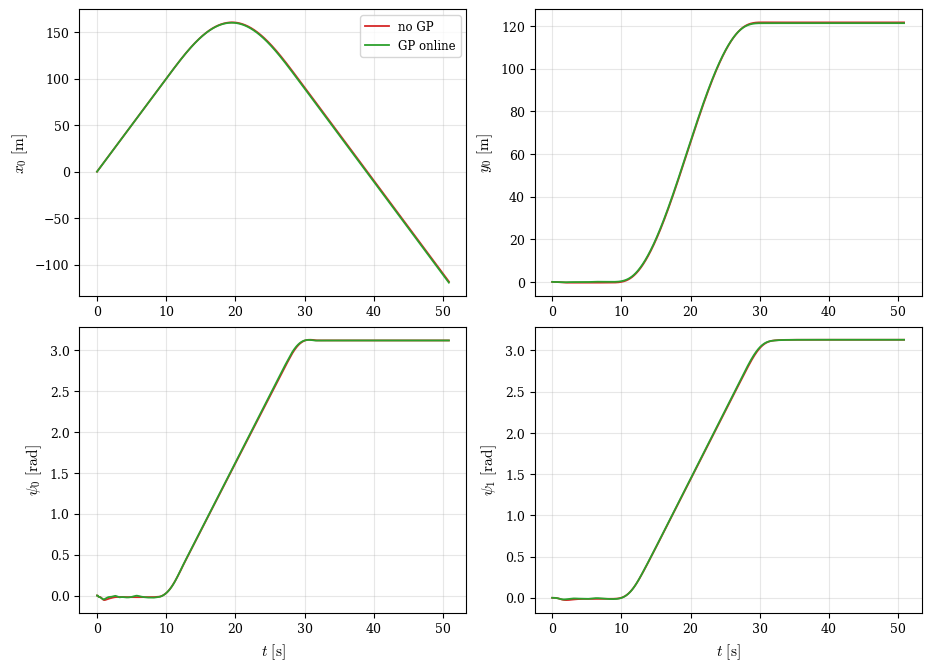

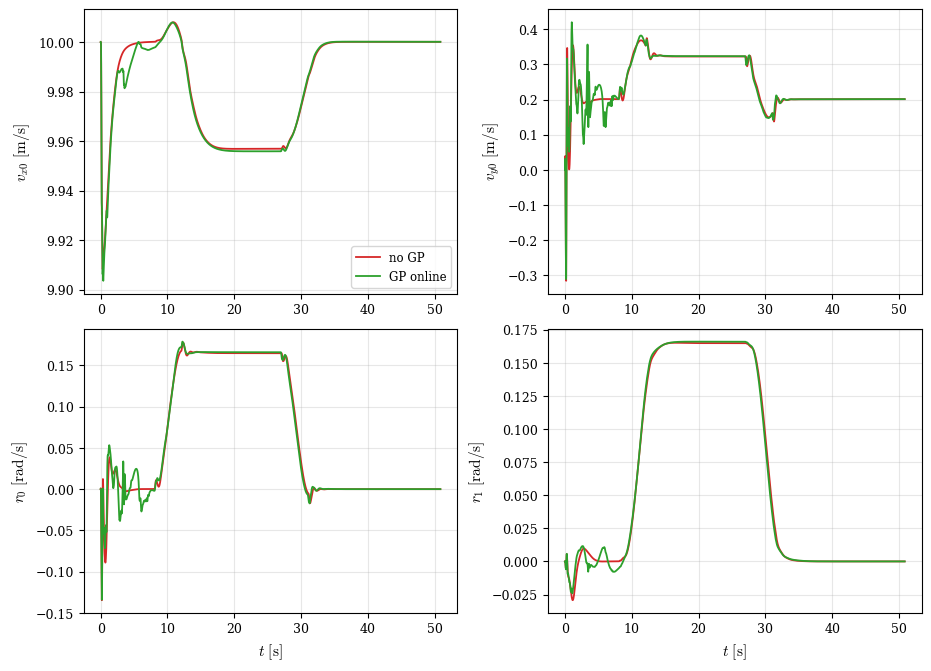

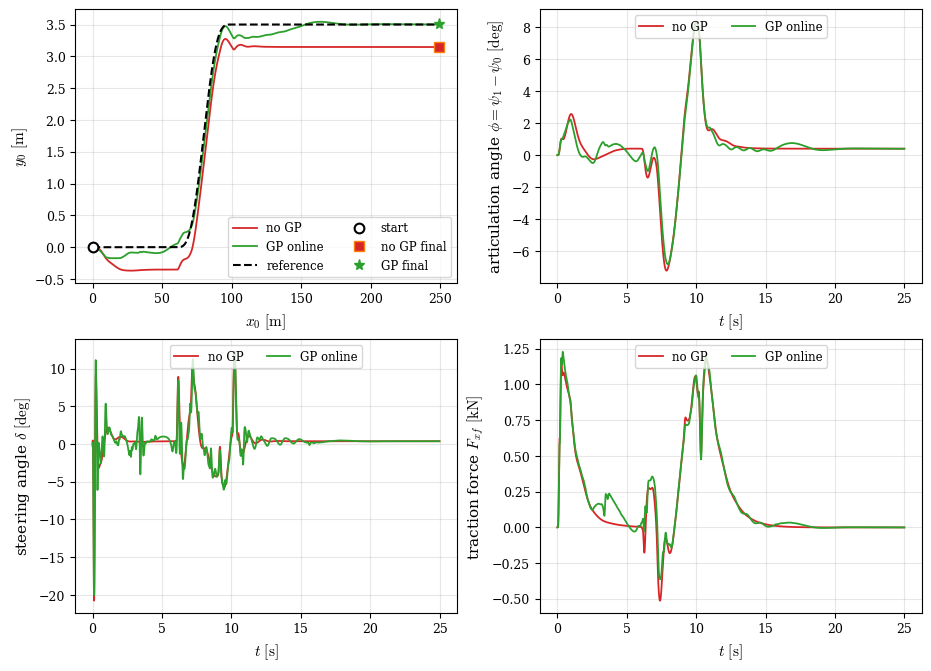

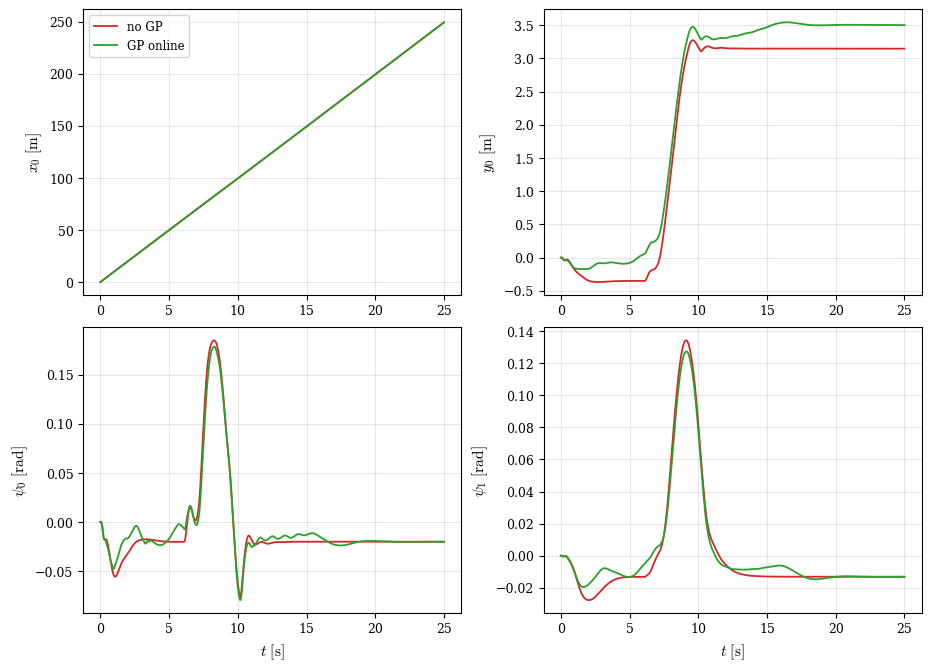

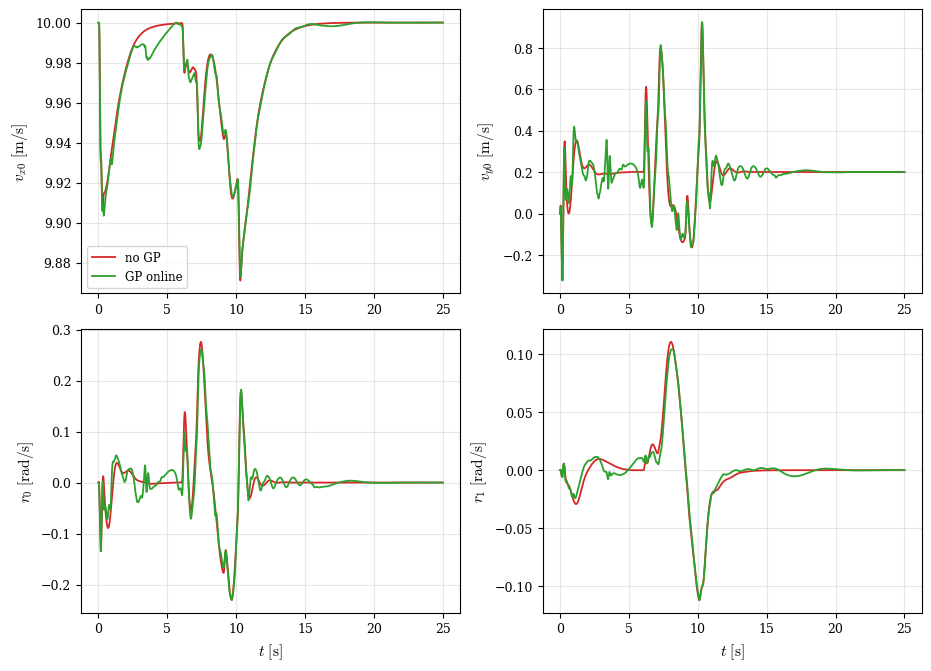

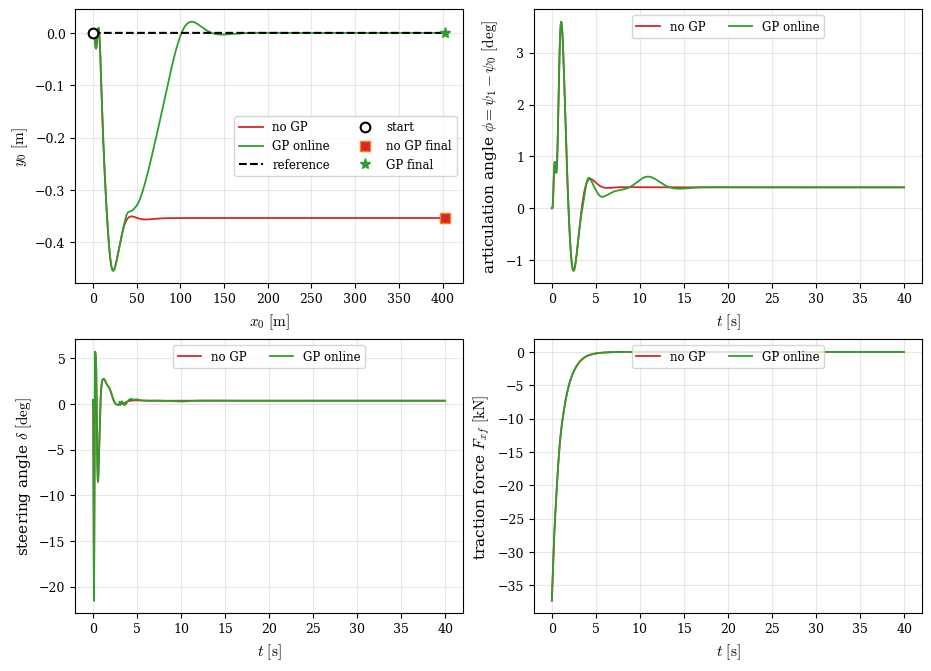

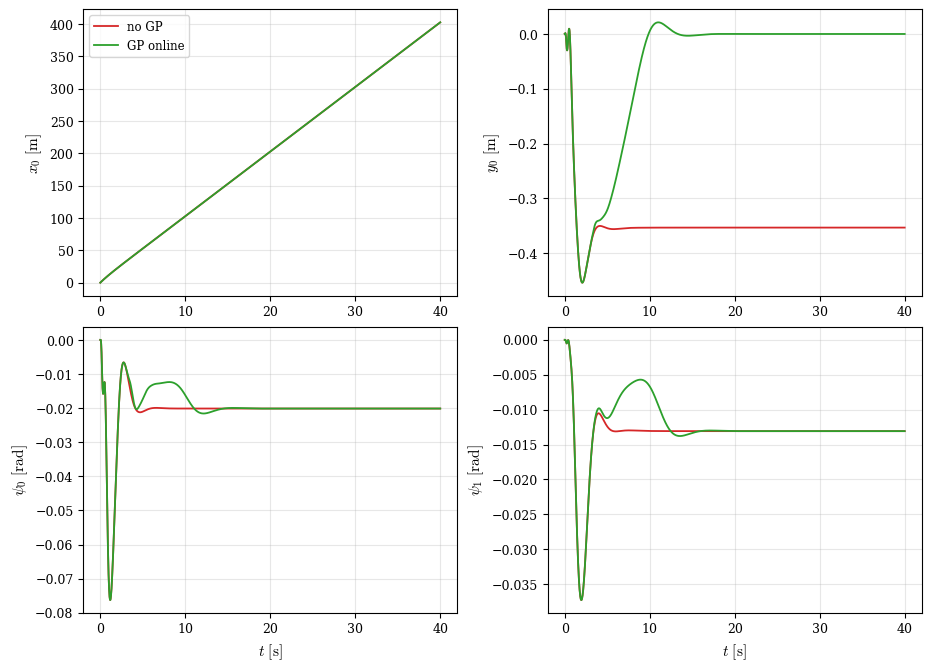

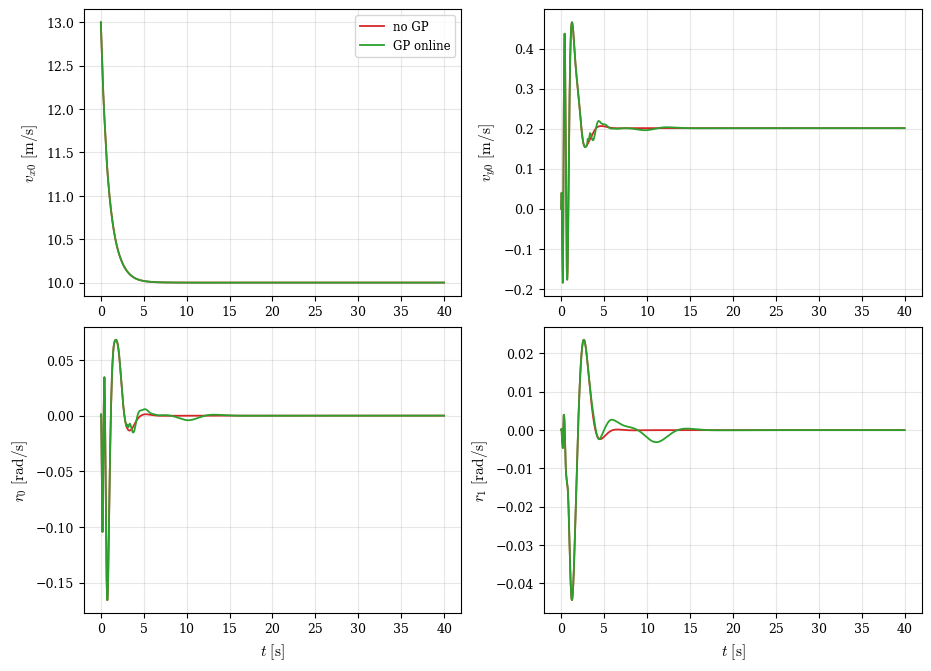

In [8]:
figures.configure(use_tex=False, png_preview=False, t_from=0.0)
figures.save_error_figures(scenario_runs, vx_ref=speed["vx_ref"], out_dir="figures_svg")
figures.save_state_figures(scenario_runs, out_dir="figures_svg_states")
plt.show()